# Assignment 8: FP-Growth Algorithm for Association Rule Mining

**Soumik Bhattacharyya**  
**MDE2026005**  

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

np.random.seed(42)


## Part A: Dataset and Transaction Preparation

### A1. Dataset Exploration

In [2]:
data = load_iris()

X = data.data
y = data.target

print("Number of transactions:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature names:")
print(data.feature_names)

print("\nClass names:")
print(data.target_names)


Number of transactions: 150
Number of features: 4

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Class names:
['setosa' 'versicolor' 'virginica']


### A2. Convert Numerical Features into Categorical Items

In [3]:
feature_names = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

quantile_values = {}

for i, feature in enumerate(feature_names):
    q1, q2 = np.quantile(X[:, i], [1/3, 2/3])
    quantile_values[feature] = (q1, q2)

print("1/3 and 2/3 quantiles:")
for feature, (q1, q2) in quantile_values.items():
    print(f"{feature}: q1 = {q1:.6f}, q2 = {q2:.6f}")


1/3 and 2/3 quantiles:
sepal_length: q1 = 5.400000, q2 = 6.300000
sepal_width: q1 = 2.900000, q2 = 3.200000
petal_length: q1 = 2.633333, q2 = 4.900000
petal_width: q1 = 0.866667, q2 = 1.600000


In [4]:
def categorize(value, q1, q2):
    if value <= q1:
        return "low"
    elif value <= q2:
        return "medium"
    return "high"


transactions = []

for row, class_value in zip(X, y):
    transaction = set()

    for i, feature in enumerate(feature_names):
        q1, q2 = quantile_values[feature]
        category = categorize(row[i], q1, q2)
        transaction.add(f"{feature}={category}")

    transaction.add(f"species={data.target_names[class_value]}")
    transactions.append(transaction)

print("First 10 transactions:")
for i, transaction in enumerate(transactions[:10], start=1):
    print(f"{i}: {sorted(transaction)}")

print("\nEvery transaction is represented as a set:")
print(all(isinstance(transaction, set) for transaction in transactions))


First 10 transactions:
1: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=high', 'species=setosa']
2: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=medium', 'species=setosa']
3: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=medium', 'species=setosa']
4: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=medium', 'species=setosa']
5: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=high', 'species=setosa']
6: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=high', 'species=setosa']
7: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=high', 'species=setosa']
8: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=high', 'species=setosa']
9: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=low', 'species=setosa']
10: ['petal_length=low', 'petal_width=low', 'sepal_length=low',

## Task 1: Inspect the Transaction Database

In [5]:
N = len(transactions)

unique_items = sorted(
    set().union(*transactions)
)

print("Total number of transactions:", N)
print("\nComplete set of unique items:")
print(unique_items)
print("\nNumber of unique items:", len(unique_items))

item_counts = {
    item: sum(item in transaction for transaction in transactions)
    for item in unique_items
}

print("\nOccurrence counts for selected items:")
for item in unique_items[:5]:
    print(f"{item}: {item_counts[item]}")


Total number of transactions: 150

Complete set of unique items:
['petal_length=high', 'petal_length=low', 'petal_length=medium', 'petal_width=high', 'petal_width=low', 'petal_width=medium', 'sepal_length=high', 'sepal_length=low', 'sepal_length=medium', 'sepal_width=high', 'sepal_width=low', 'sepal_width=medium', 'species=setosa', 'species=versicolor', 'species=virginica']

Number of unique items: 15

Occurrence counts for selected items:
petal_length=high: 46
petal_length=low: 50
petal_length=medium: 54
petal_width=high: 48
petal_width=low: 50


### Task 1 Observation

There are 15 unique items, with each numerical feature split into three categories and the species giving three more items. The selected item counts are fairly close, so the categories are reasonably balanced.

## Task 2: Implement Support

In [6]:
def support(itemset, transactions):
    itemset = set(itemset)
    count = sum(itemset.issubset(transaction) for transaction in transactions)
    return count / len(transactions)


support_tests = [
    {unique_items[0]},
    {unique_items[1]},
    {unique_items[2]},
    {unique_items[0], unique_items[1]},
    {unique_items[0], unique_items[2]},
    {unique_items[1], unique_items[2]}
]

support_test_rows = []

for itemset in support_tests:
    count = sum(itemset.issubset(transaction) for transaction in transactions)
    support_value = support(itemset, transactions)

    support_test_rows.append({
        "Itemset": tuple(sorted(itemset)),
        "Occurrence Count": count,
        "Support (%)": support_value * 100
    })

support_test_df = pd.DataFrame(support_test_rows)
print(support_test_df.to_string(index=False))


                                 Itemset  Occurrence Count  Support (%)
                    (petal_length=high,)                46    30.666667
                     (petal_length=low,)                50    33.333333
                  (petal_length=medium,)                54    36.000000
   (petal_length=high, petal_length=low)                 0     0.000000
(petal_length=high, petal_length=medium)                 0     0.000000
 (petal_length=low, petal_length=medium)                 0     0.000000


## Task 3: Support and Confidence for an Association Rule

In [7]:
def confidence(antecedent, consequent, transactions):
    antecedent = set(antecedent)
    consequent = set(consequent)

    union = antecedent | consequent

    antecedent_count = sum(
        antecedent.issubset(transaction)
        for transaction in transactions
    )

    union_count = sum(
        union.issubset(transaction)
        for transaction in transactions
    )

    if antecedent_count == 0:
        return 0.0

    return union_count / antecedent_count


example_antecedent = {"petal_length=low"}
example_consequent = {"species=setosa"}

example_union = example_antecedent | example_consequent

example_antecedent_count = sum(
    example_antecedent.issubset(transaction)
    for transaction in transactions
)

example_union_count = sum(
    example_union.issubset(transaction)
    for transaction in transactions
)

example_support = support(example_union, transactions)
example_confidence = confidence(
    example_antecedent,
    example_consequent,
    transactions
)

print("Rule:", example_antecedent, "->", example_consequent)
print("Antecedent count:", example_antecedent_count)
print("Union count:", example_union_count)
print("Support:", example_union_count, "/", N, "=", example_support)
print(
    "Confidence:",
    example_union_count,
    "/",
    example_antecedent_count,
    "=",
    example_confidence
)

reverse_confidence = confidence(
    example_consequent,
    example_antecedent,
    transactions
)

print("\nReverse rule confidence:")
print(example_consequent, "->", example_antecedent, "=", reverse_confidence)


Rule: {'petal_length=low'} -> {'species=setosa'}
Antecedent count: 50
Union count: 50
Support: 50 / 150 = 0.3333333333333333
Confidence: 50 / 50 = 1.0

Reverse rule confidence:
{'species=setosa'} -> {'petal_length=low'} = 1.0


### Task 3 Observation

The rule `petal_length=low → species=setosa` has 33.33% support and 100% confidence. Here both directions also have confidence 1.0 because the two items occur together in exactly the same 50 transactions.

## Task 4: Set Minimum Thresholds

In [8]:
MIN_SUPPORT = 0.20
MIN_CONFIDENCE = 0.70

print("Minimum support:", MIN_SUPPORT)
print("Minimum confidence:", MIN_CONFIDENCE)
print("Minimum support count:", int(np.ceil(MIN_SUPPORT * N)))


Minimum support: 0.2
Minimum confidence: 0.7
Minimum support count: 30


### Task 4 Observation

Minimum support controls how often an itemset must occur to be considered frequent, while confidence controls how reliable a rule must be. Using both removes rare patterns and weak rules.

# Part B: FP-Growth Algorithm

## Task 5: Find Frequent Items and Build the Header Table

In [9]:
min_support_count = int(np.ceil(MIN_SUPPORT * N))

frequent_item_counts = {
    item: count
    for item, count in item_counts.items()
    if count >= min_support_count
}

def item_sort_key(item):
    return (-frequent_item_counts[item], item)


global_order = sorted(
    frequent_item_counts,
    key=item_sort_key
)

filtered_transactions = []

for transaction in transactions:
    filtered = [
        item
        for item in transaction
        if item in frequent_item_counts
    ]
    filtered.sort(key=item_sort_key)
    filtered_transactions.append(filtered)

print("Global frequency order:")
for rank, item in enumerate(global_order, start=1):
    print(rank, item, frequent_item_counts[item])

print("\nExample transactions before and after filtering/reordering:")
for i in range(min(5, N)):
    print(f"Transaction {i + 1}")
    print("Before:", sorted(transactions[i]))
    print("After :", filtered_transactions[i])


Global frequency order:
1 sepal_width=low 57
2 sepal_length=medium 56
3 petal_length=medium 54
4 petal_width=medium 52
5 sepal_length=low 52
6 petal_length=low 50
7 petal_width=low 50
8 sepal_width=medium 50
9 species=setosa 50
10 species=versicolor 50
11 species=virginica 50
12 petal_width=high 48
13 petal_length=high 46
14 sepal_width=high 43
15 sepal_length=high 42

Example transactions before and after filtering/reordering:
Transaction 1
Before: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=high', 'species=setosa']
After : ['sepal_length=low', 'petal_length=low', 'petal_width=low', 'species=setosa', 'sepal_width=high']
Transaction 2
Before: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=medium', 'species=setosa']
After : ['sepal_length=low', 'petal_length=low', 'petal_width=low', 'sepal_width=medium', 'species=setosa']
Transaction 3
Before: ['petal_length=low', 'petal_width=low', 'sepal_length=low', 'sepal_width=medium', 'species

## Task 6: Implement FP-Tree Node Structure

In [10]:
class FPNode:
    def __init__(self, item=None, count=0, parent=None):
        self.item = item
        self.count = count
        self.parent = parent
        self.children = {}
        self.node_link = None

    def increment(self, count=1):
        self.count += count


def add_node_link(header_table, node):
    item = node.item

    if header_table[item]["head"] is None:
        header_table[item]["head"] = node
        return

    current = header_table[item]["head"]

    while current.node_link is not None:
        current = current.node_link

    current.node_link = node


## Task 7: Construct the FP-Tree

In [11]:
def create_header_table(item_counts):
    return {
        item: {
            "count": count,
            "head": None
        }
        for item, count in item_counts.items()
    }


def insert_transaction(tree, header_table, ordered_items, count=1):
    current = tree

    for item in ordered_items:
        if item in current.children:
            child = current.children[item]
            child.increment(count)
        else:
            child = FPNode(
                item=item,
                count=count,
                parent=current
            )
            current.children[item] = child
            add_node_link(header_table, child)

        current = child


def build_fp_tree(ordered_transactions, frequent_counts):
    header_table = create_header_table(frequent_counts)
    root = FPNode(item=None, count=0)

    for transaction in ordered_transactions:
        if transaction:
            insert_transaction(
                root,
                header_table,
                transaction
            )

    return root, header_table


fp_tree, header_table = build_fp_tree(
    filtered_transactions,
    frequent_item_counts
)

print("Global frequency order:")
print(global_order)


Global frequency order:
['sepal_width=low', 'sepal_length=medium', 'petal_length=medium', 'petal_width=medium', 'sepal_length=low', 'petal_length=low', 'petal_width=low', 'sepal_width=medium', 'species=setosa', 'species=versicolor', 'species=virginica', 'petal_width=high', 'petal_length=high', 'sepal_width=high', 'sepal_length=high']


In [12]:
def print_tree(node, level=0):
    if node.item is None:
        print("  " * level + "ROOT")
    else:
        print("  " * level + f"{node.item}: {node.count}")

    for child in node.children.values():
        print_tree(child, level + 1)


print_tree(fp_tree)


ROOT
  sepal_length=low: 43
    petal_length=low: 43
      petal_width=low: 43
        species=setosa: 28
          sepal_width=high: 28
        sepal_width=medium: 15
          species=setosa: 15
  sepal_width=low: 57
    sepal_length=low: 2
      petal_length=low: 2
        petal_width=low: 2
          species=setosa: 2
    sepal_length=medium: 37
      petal_length=medium: 27
        petal_width=medium: 24
          species=versicolor: 24
        species=virginica: 3
          petal_width=high: 3
      petal_width=medium: 4
        species=versicolor: 1
          petal_length=high: 1
        species=virginica: 3
          petal_length=high: 3
      species=virginica: 6
        petal_width=high: 6
          petal_length=high: 6
    petal_length=medium: 10
      petal_width=medium: 9
        species=versicolor: 4
          sepal_length=high: 4
        sepal_length=low: 5
          species=versicolor: 5
      sepal_length=low: 1
        species=virginica: 1
          petal_width=high: 

### Task 7 Observation

The FP-tree shares many prefixes, especially for the setosa transactions. The linked-node sums also match the original frequencies, which confirms that the tree was built correctly.

## Task 8: Implement Node-Link Traversal

In [13]:
def traverse_node_links(item, header_table):
    nodes = []
    node = header_table[item]["head"]

    while node is not None:
        nodes.append(node)
        node = node.node_link

    return nodes


node_link_rows = []

for item in global_order[:5]:
    nodes = traverse_node_links(item, header_table)
    linked_counts = [node.count for node in nodes]
    linked_sum = sum(linked_counts)

    node_link_rows.append({
        "Item": item,
        "Original Count": frequent_item_counts[item],
        "Node Counts": linked_counts,
        "Linked-Node Sum": linked_sum
    })

node_link_df = pd.DataFrame(node_link_rows)
print(node_link_df.to_string(index=False))


               Item  Original Count         Node Counts  Linked-Node Sum
    sepal_width=low              57                [57]               57
sepal_length=medium              56            [19, 37]               56
petal_length=medium              54     [7, 27, 10, 10]               54
 petal_width=medium              52 [7, 24, 9, 7, 4, 1]               52
   sepal_length=low              52    [43, 2, 5, 1, 1]               52


### Task 8 Observation

The node links make it easy to find all occurrences of an item without scanning the whole tree. The linked-node sums match the original counts for the checked items.

## Task 9: Generate Conditional Pattern Bases

In [14]:
def find_prefix_paths(item, header_table):
    conditional_patterns = []
    node = header_table[item]["head"]

    while node is not None:
        path = []
        parent = node.parent

        while parent is not None and parent.item is not None:
            path.append(parent.item)
            parent = parent.parent

        path.reverse()

        if path:
            conditional_patterns.append((path, node.count))

        node = node.node_link

    return conditional_patterns


selected_conditional_items = global_order[:min(5, len(global_order))]

conditional_pattern_bases = {}

for item in selected_conditional_items:
    paths = find_prefix_paths(item, header_table)
    conditional_pattern_bases[item] = paths

    print(f"\nConditional pattern base for: {item}")
    if paths:
        for path, count in paths:
            print(f"  {path} : {count}")
    else:
        print("  []")



Conditional pattern base for: sepal_width=low
  []

Conditional pattern base for: sepal_length=medium
  ['sepal_width=low'] : 37

Conditional pattern base for: petal_length=medium
  ['sepal_width=low', 'sepal_length=medium'] : 27
  ['sepal_width=low'] : 10
  ['sepal_length=medium'] : 10

Conditional pattern base for: petal_width=medium
  ['petal_length=medium'] : 7
  ['sepal_width=low', 'sepal_length=medium', 'petal_length=medium'] : 24
  ['sepal_width=low', 'petal_length=medium'] : 9
  ['sepal_length=medium', 'petal_length=medium'] : 7
  ['sepal_width=low', 'sepal_length=medium'] : 4

Conditional pattern base for: sepal_length=low
  ['sepal_width=low'] : 2
  ['sepal_width=low', 'petal_length=medium', 'petal_width=medium'] : 5
  ['petal_length=medium', 'petal_width=medium'] : 1
  ['sepal_width=low', 'petal_length=medium'] : 1


### Task 9 Observation

The conditional pattern bases contain the prefixes that occur before each selected suffix item. Their counts show how many transactions share each of those prefixes.

## Task 10: Build Conditional FP-Trees

In [15]:
def build_conditional_tree(pattern_base, min_support_count):
    weighted_item_counts = {}

    for path, path_count in pattern_base:
        for item in path:
            weighted_item_counts[item] = (
                weighted_item_counts.get(item, 0) + path_count
            )

    conditional_frequent_counts = {
        item: count
        for item, count in weighted_item_counts.items()
        if count >= min_support_count
    }

    if not conditional_frequent_counts:
        return None, {}, []

    conditional_order = sorted(
        conditional_frequent_counts,
        key=lambda item: (
            -conditional_frequent_counts[item],
            item
        )
    )

    conditional_tree = FPNode(item=None, count=0)
    conditional_header = create_header_table(
        conditional_frequent_counts
    )

    for path, path_count in pattern_base:
        ordered_path = [
            item
            for item in path
            if item in conditional_frequent_counts
        ]

        ordered_path.sort(
            key=lambda item: (
                -conditional_frequent_counts[item],
                item
            )
        )

        if ordered_path:
            insert_transaction(
                conditional_tree,
                conditional_header,
                ordered_path,
                count=path_count
            )

    return (
        conditional_tree,
        conditional_header,
        conditional_order
    )


conditional_tree_records = []

for suffix_item in selected_conditional_items[:3]:
    pattern_base = conditional_pattern_bases[suffix_item]

    conditional_tree, conditional_header, conditional_order = (
        build_conditional_tree(
            pattern_base,
            min_support_count
        )
    )

    conditional_tree_records.append({
        "Suffix": suffix_item,
        "Tree": conditional_tree,
        "Header": conditional_header,
        "Order": conditional_order
    })

    print(f"\nConditional FP-tree for suffix: {suffix_item}")
    if conditional_tree is None:
        print("  Empty conditional tree")
    else:
        print("  Conditional frequency order:", conditional_order)
        print_tree(conditional_tree)



Conditional FP-tree for suffix: sepal_width=low
  Empty conditional tree

Conditional FP-tree for suffix: sepal_length=medium
  Conditional frequency order: ['sepal_width=low']
ROOT
  sepal_width=low: 37

Conditional FP-tree for suffix: petal_length=medium
  Conditional frequency order: ['sepal_length=medium', 'sepal_width=low']
ROOT
  sepal_length=medium: 37
    sepal_width=low: 27
  sepal_width=low: 10


### Task 10 Observation

The conditional trees are much smaller than the main tree because they only contain patterns relevant to one suffix item. For some suffixes, no conditional tree is needed at all.

## Task 11: Complete the FP-Growth Algorithm

In [16]:
def is_single_path(tree):
    current = tree

    while current is not None:
        if len(current.children) > 1:
            return False

        if len(current.children) == 0:
            return True

        current = next(iter(current.children.values()))

    return True


def get_single_path_nodes(tree):
    nodes = []
    current = tree

    while current is not None and current.children:
        current = next(iter(current.children.values()))
        nodes.append(current)

    return nodes


def fp_growth(tree, header_table, suffix, min_support_count, results):
    if tree is None or not header_table:
        return

    if is_single_path(tree):
        path_nodes = get_single_path_nodes(tree)

        for r in range(1, len(path_nodes) + 1):
            # Generate every non-empty combination of the single path.
            import itertools

            for combination in itertools.combinations(
                path_nodes,
                r
            ):
                items = tuple(
                    sorted(
                        [node.item for node in combination] + list(suffix)
                    )
                )

                count = min(
                    node.count for node in combination
                )

                results[items] = max(
                    results.get(items, 0),
                    count
                )

        return

    items_by_count = sorted(
        header_table.keys(),
        key=lambda item: (
            header_table[item]["count"],
            item
        )
    )

    for item in items_by_count:
        new_suffix = tuple(sorted(list(suffix) + [item]))

        item_count = header_table[item]["count"]

        results[new_suffix] = max(
            results.get(new_suffix, 0),
            item_count
        )

        pattern_base = find_prefix_paths(
            item,
            header_table
        )

        conditional_tree, conditional_header, _ = (
            build_conditional_tree(
                pattern_base,
                min_support_count
            )
        )

        if conditional_tree is not None and conditional_header:
            fp_growth(
                conditional_tree,
                conditional_header,
                new_suffix,
                min_support_count,
                results
            )


frequent_itemsets = {}

fp_growth(
    fp_tree,
    header_table,
    tuple(),
    min_support_count,
    frequent_itemsets
)

frequent_itemsets = {
    tuple(sorted(itemset)): count
    for itemset, count in frequent_itemsets.items()
    if count >= min_support_count
}

print("Number of frequent itemsets:", len(frequent_itemsets))


Number of frequent itemsets: 63


## Task 12: Display All Frequent Itemsets

In [17]:
def frequent_itemsets_by_size(frequent_itemsets):
    grouped = {}

    for itemset, count in frequent_itemsets.items():
        k = len(itemset)
        grouped.setdefault(k, []).append((itemset, count))

    return {
        k: sorted(values)
        for k, values in sorted(grouped.items())
    }


grouped_itemsets = frequent_itemsets_by_size(
    frequent_itemsets
)

all_itemset_rows = []

for k, itemsets in grouped_itemsets.items():
    for itemset, count in itemsets:
        all_itemset_rows.append({
            "k": k,
            "Itemset": itemset,
            "Occurrence Count": count,
            "Support (%)": count / N * 100
        })

all_frequent_itemsets_df = pd.DataFrame(all_itemset_rows)

if len(all_frequent_itemsets_df) > 0:
    print(all_frequent_itemsets_df.to_string(index=False))
else:
    print("No frequent itemsets found.")

print("\nTotal frequent itemsets:", len(frequent_itemsets))
print(
    "Largest frequent itemset size:",
    max(map(len, frequent_itemsets)) if frequent_itemsets else 0
)


 k                                                                            Itemset  Occurrence Count  Support (%)
 1                                                               (petal_length=high,)                46    30.666667
 1                                                                (petal_length=low,)                50    33.333333
 1                                                             (petal_length=medium,)                54    36.000000
 1                                                                (petal_width=high,)                48    32.000000
 1                                                                 (petal_width=low,)                50    33.333333
 1                                                              (petal_width=medium,)                52    34.666667
 1                                                               (sepal_length=high,)                42    28.000000
 1                                                              

### Task 12 Observation

At 20% minimum support, FP-Growth found 63 frequent itemsets, with the largest containing 4 items. Most of the frequent patterns are smaller itemsets.

## Task 13: Verify Frequent-Itemset Support

In [18]:
verification_itemsets = sorted(
    frequent_itemsets,
    key=lambda itemset: (len(itemset), itemset)
)[:min(10, len(frequent_itemsets))]

verification_rows = []

for itemset in verification_itemsets:
    fp_count = frequent_itemsets[itemset]
    direct_count = sum(
        set(itemset).issubset(transaction)
        for transaction in transactions
    )

    verification_rows.append({
        "Itemset": itemset,
        "FP-Growth Count": fp_count,
        "Direct Count": direct_count,
        "Match": fp_count == direct_count
    })

verification_df = pd.DataFrame(verification_rows)
print(verification_df.to_string(index=False))


               Itemset  FP-Growth Count  Direct Count  Match
  (petal_length=high,)               46            46   True
   (petal_length=low,)               50            50   True
(petal_length=medium,)               54            54   True
   (petal_width=high,)               48            48   True
    (petal_width=low,)               50            50   True
 (petal_width=medium,)               52            52   True
  (sepal_length=high,)               42            42   True
   (sepal_length=low,)               52            52   True
(sepal_length=medium,)               56            56   True
   (sepal_width=high,)               43            43   True


### Task 13 Observation

The FP-Growth counts match the direct counts for the checked itemsets. This shows that the transaction filtering and weighted conditional paths are preserving the support counts correctly.

## Task 14: Generate Association Rules from Frequent Itemsets

In [19]:
def generate_nonempty_proper_subsets(itemset):
    import itertools

    itemset = tuple(itemset)

    for r in range(1, len(itemset)):
        for subset in itertools.combinations(itemset, r):
            yield set(subset)


def generate_rules(
    frequent_itemsets,
    transactions,
    min_confidence=0.70
):
    rules = []

    for itemset, itemset_count in frequent_itemsets.items():
        if len(itemset) < 2:
            continue

        itemset_set = set(itemset)

        for antecedent in generate_nonempty_proper_subsets(
            itemset
        ):
            consequent = itemset_set - antecedent

            antecedent_count = sum(
                antecedent.issubset(transaction)
                for transaction in transactions
            )

            if antecedent_count == 0:
                continue

            union_count = sum(
                itemset_set.issubset(transaction)
                for transaction in transactions
            )

            rule_support = union_count / len(transactions)
            rule_confidence = union_count / antecedent_count

            if rule_confidence >= min_confidence:
                rules.append({
                    "Antecedent": tuple(sorted(antecedent)),
                    "Consequent": tuple(sorted(consequent)),
                    "Support": rule_support,
                    "Confidence": rule_confidence,
                    "Support Count": union_count
                })

    rules.sort(
        key=lambda row: (
            -row["Confidence"],
            -row["Support"]
        )
    )

    return rules


strong_rules = generate_rules(
    frequent_itemsets,
    transactions,
    MIN_CONFIDENCE
)

strong_rules_df = pd.DataFrame(strong_rules)

if len(strong_rules_df) > 0:
    print(
        strong_rules_df[
            [
                "Antecedent",
                "Consequent",
                "Support",
                "Confidence",
                "Support Count"
            ]
        ].to_string(index=False)
    )
else:
    print("No strong rules found.")

print("\nNumber of strong rules:", len(strong_rules))


                                                    Antecedent                                               Consequent  Support  Confidence  Support Count
                                           (petal_length=low,)                                       (petal_width=low,) 0.333333    1.000000             50
                                            (petal_width=low,)                                      (petal_length=low,) 0.333333    1.000000             50
                                           (petal_length=low,)                                        (species=setosa,) 0.333333    1.000000             50
                                             (species=setosa,)                                      (petal_length=low,) 0.333333    1.000000             50
                                            (petal_width=low,)                                        (species=setosa,) 0.333333    1.000000             50
                                             (species=setosa,)  

## Task 15: Present the Strong Association Rules

In [20]:
if len(strong_rules_df) > 0:
    display_rules_df = strong_rules_df.head(10).copy()

    display_rules_df["Support (%)"] = (
        display_rules_df["Support"] * 100
    )

    display_rules_df["Confidence (%)"] = (
        display_rules_df["Confidence"] * 100
    )

    display(
        display_rules_df[
            [
                "Antecedent",
                "Consequent",
                "Support (%)",
                "Confidence (%)"
            ]
        ]
    )
else:
    print("No rules available for display.")


,Antecedent,Consequent,Support (%),Confidence (%)
0,"(petal_length=low,)","(petal_width=low,)",33.333333,100.0
1,"(petal_width=low,)","(petal_length=low,)",33.333333,100.0
2,"(petal_length=low,)","(species=setosa,)",33.333333,100.0
3,"(species=setosa,)","(petal_length=low,)",33.333333,100.0
4,"(petal_width=low,)","(species=setosa,)",33.333333,100.0
5,"(species=setosa,)","(petal_width=low,)",33.333333,100.0
6,"(petal_length=low,)","(petal_width=low, species=setosa)",33.333333,100.0
7,"(petal_width=low,)","(petal_length=low, species=setosa)",33.333333,100.0
8,"(species=setosa,)","(petal_length=low, petal_width=low)",33.333333,100.0
9,"(petal_length=low, petal_width=low)","(species=setosa,)",33.333333,100.0


### Task 15 Observation

A large number of strong rules have confidence 1.0, mainly because some categorical combinations occur together very consistently. The rules describe co-occurrence, not a cause-and-effect relationship.

## Task 16: Manual Rule Calculation

In [21]:
if len(strong_rules) > 0:
    selected_rule = strong_rules[0]

    A = set(selected_rule["Antecedent"])
    B = set(selected_rule["Consequent"])

    count_A = sum(
        A.issubset(transaction)
        for transaction in transactions
    )

    count_AB = sum(
        (A | B).issubset(transaction)
        for transaction in transactions
    )

    manual_support = count_AB / N
    manual_confidence = count_AB / count_A

    print("Antecedent A:", A)
    print("Consequent B:", B)
    print("count(A):", count_A)
    print("count(A ∪ B):", count_AB)
    print("Support =", count_AB, "/", N, "=", manual_support)
    print(
        "Confidence =",
        count_AB,
        "/",
        count_A,
        "=",
        manual_confidence
    )

    print("\nProgram output:")
    print("Support:", selected_rule["Support"])
    print("Confidence:", selected_rule["Confidence"])
else:
    print("No strong rule is available.")


Antecedent A: {'petal_length=low'}
Consequent B: {'petal_width=low'}
count(A): 50
count(A ∪ B): 50
Support = 50 / 150 = 0.3333333333333333
Confidence = 50 / 50 = 1.0

Program output:
Support: 0.3333333333333333
Confidence: 1.0


### Task 16 Observation

For the selected rule, the manual calculation gives 33.33% support and 100% confidence. These values are the same as the program output.

## Task 17: Effect of Minimum Support

In [22]:
support_thresholds = [0.15, 0.20, 0.25]
support_experiment_rows = []

support_experiment_itemsets = {}

for threshold in support_thresholds:
    threshold_count = int(np.ceil(threshold * N))

    threshold_frequent_counts = {
        item: count
        for item, count in item_counts.items()
        if count >= threshold_count
    }

    threshold_order = sorted(
        threshold_frequent_counts,
        key=lambda item: (
            -threshold_frequent_counts[item],
            item
        )
    )

    threshold_transactions = []

    for transaction in transactions:
        filtered = [
            item
            for item in transaction
            if item in threshold_frequent_counts
        ]
        filtered.sort(
            key=lambda item: (
                -threshold_frequent_counts[item],
                item
            )
        )
        threshold_transactions.append(filtered)

    threshold_tree, threshold_header = build_fp_tree(
        threshold_transactions,
        threshold_frequent_counts
    )

    threshold_itemsets = {}

    fp_growth(
        threshold_tree,
        threshold_header,
        tuple(),
        threshold_count,
        threshold_itemsets
    )

    threshold_itemsets = {
        tuple(sorted(itemset)): count
        for itemset, count in threshold_itemsets.items()
        if count >= threshold_count
    }

    support_experiment_itemsets[threshold] = threshold_itemsets

    sizes = {}
    for itemset in threshold_itemsets:
        sizes[len(itemset)] = sizes.get(len(itemset), 0) + 1

    max_k = max(sizes) if sizes else 0

    row = {
        "Minimum Support": threshold,
        "1-itemsets": sizes.get(1, 0),
        "2-itemsets": sizes.get(2, 0),
        "3-itemsets": sizes.get(3, 0),
        "Higher-level itemsets": sum(
            count
            for k, count in sizes.items()
            if k >= 4
        ),
        "Total Frequent Itemsets": len(threshold_itemsets),
        "Largest k": max_k
    }

    support_experiment_rows.append(row)

support_experiment_df = pd.DataFrame(
    support_experiment_rows
)

print(support_experiment_df.to_string(index=False))


 Minimum Support  1-itemsets  2-itemsets  3-itemsets  Higher-level itemsets  Total Frequent Itemsets  Largest k
            0.15          15          27          24                     13                       79          5
            0.20          15          25          18                      5                       63          4
            0.25          15          12           6                      1                       34          4


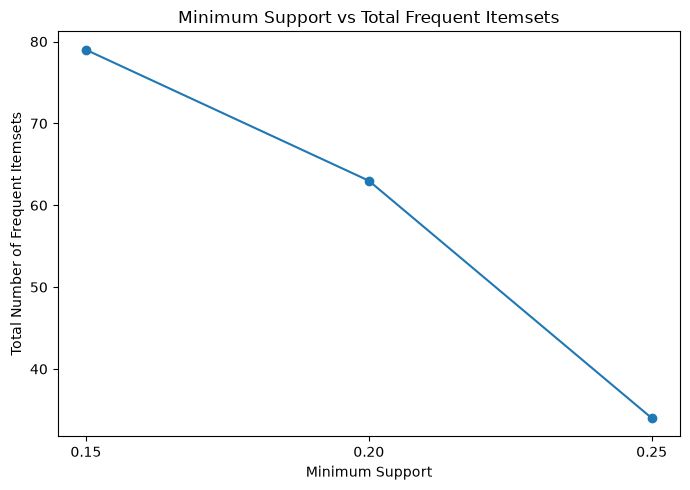

In [23]:
plt.figure(figsize=(7, 5))

plt.plot(
    support_experiment_df["Minimum Support"],
    support_experiment_df["Total Frequent Itemsets"],
    marker="o"
)

plt.xlabel("Minimum Support")
plt.ylabel("Total Number of Frequent Itemsets")
plt.title("Minimum Support vs Total Frequent Itemsets")
plt.xticks(support_thresholds)
plt.tight_layout()
plt.show()


### Task 17 Observation

Lowering minimum support increases the number of frequent patterns: 79 at 0.15, 63 at 0.20 and 34 at 0.25. The largest itemset also becomes smaller as the threshold increases.

## Task 18: Effect of Minimum Confidence

In [24]:
confidence_thresholds = [0.50, 0.70, 0.90]
confidence_experiment_rows = []
confidence_experiment_rules = {}

for threshold in confidence_thresholds:
    rules = generate_rules(
        frequent_itemsets,
        transactions,
        min_confidence=threshold
    )

    confidence_experiment_rules[threshold] = rules

    confidence_experiment_rows.append({
        "Minimum Confidence": threshold,
        "Number of Strong Rules": len(rules)
    })

confidence_experiment_df = pd.DataFrame(
    confidence_experiment_rows
)

print(confidence_experiment_df.to_string(index=False))


 Minimum Confidence  Number of Strong Rules
                0.5                     228
                0.7                     145
                0.9                      95


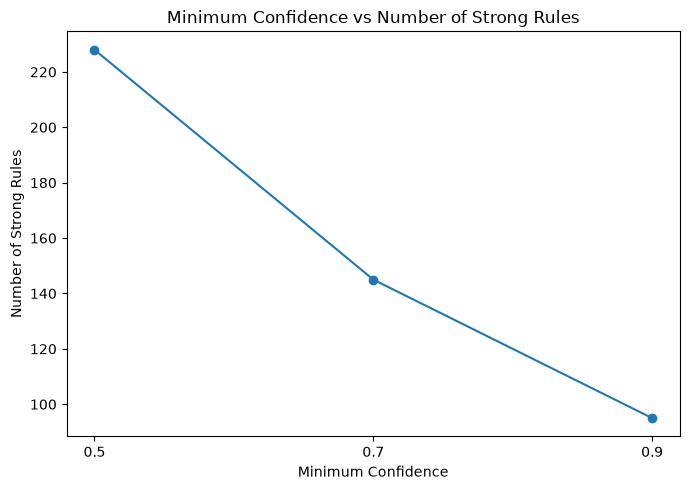

In [25]:
plt.figure(figsize=(7, 5))

plt.plot(
    confidence_experiment_df["Minimum Confidence"],
    confidence_experiment_df["Number of Strong Rules"],
    marker="o"
)

plt.xlabel("Minimum Confidence")
plt.ylabel("Number of Strong Rules")
plt.title("Minimum Confidence vs Number of Strong Rules")
plt.xticks(confidence_thresholds)
plt.tight_layout()
plt.show()


### Task 18 Observation

The number of strong rules falls from 228 to 145 and then 95 as minimum confidence increases from 0.50 to 0.70 and 0.90. A higher confidence threshold keeps only the more reliable rules.

## Task 19: Required Visualizations

### Frequent Itemsets by Itemset Size

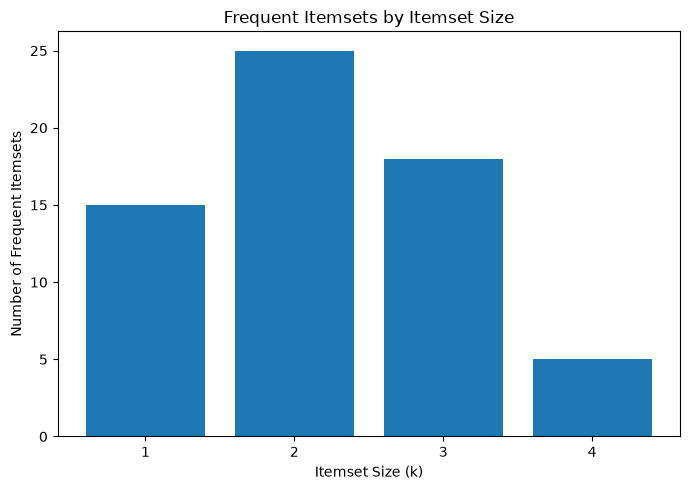

In [26]:
itemset_size_counts = (
    all_frequent_itemsets_df
    .groupby("k")
    .size()
    .reset_index(name="Number of Frequent Itemsets")
    if len(all_frequent_itemsets_df) > 0
    else pd.DataFrame(columns=["k", "Number of Frequent Itemsets"])
)

plt.figure(figsize=(7, 5))

if len(itemset_size_counts) > 0:
    plt.bar(
        itemset_size_counts["k"],
        itemset_size_counts["Number of Frequent Itemsets"]
    )

plt.xlabel("Itemset Size (k)")
plt.ylabel("Number of Frequent Itemsets")
plt.title("Frequent Itemsets by Itemset Size")
plt.xticks(
    itemset_size_counts["k"]
    if len(itemset_size_counts) > 0
    else []
)
plt.tight_layout()
plt.show()


### Support versus Confidence for Final Strong Rules

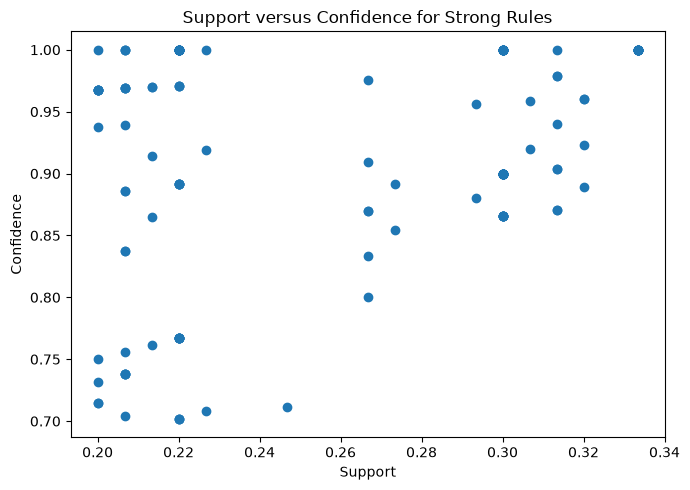

In [27]:
plt.figure(figsize=(7, 5))

if len(strong_rules_df) > 0:
    plt.scatter(
        strong_rules_df["Support"],
        strong_rules_df["Confidence"]
    )

plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support versus Confidence for Strong Rules")
plt.tight_layout()
plt.show()


### FP-Tree Visualization

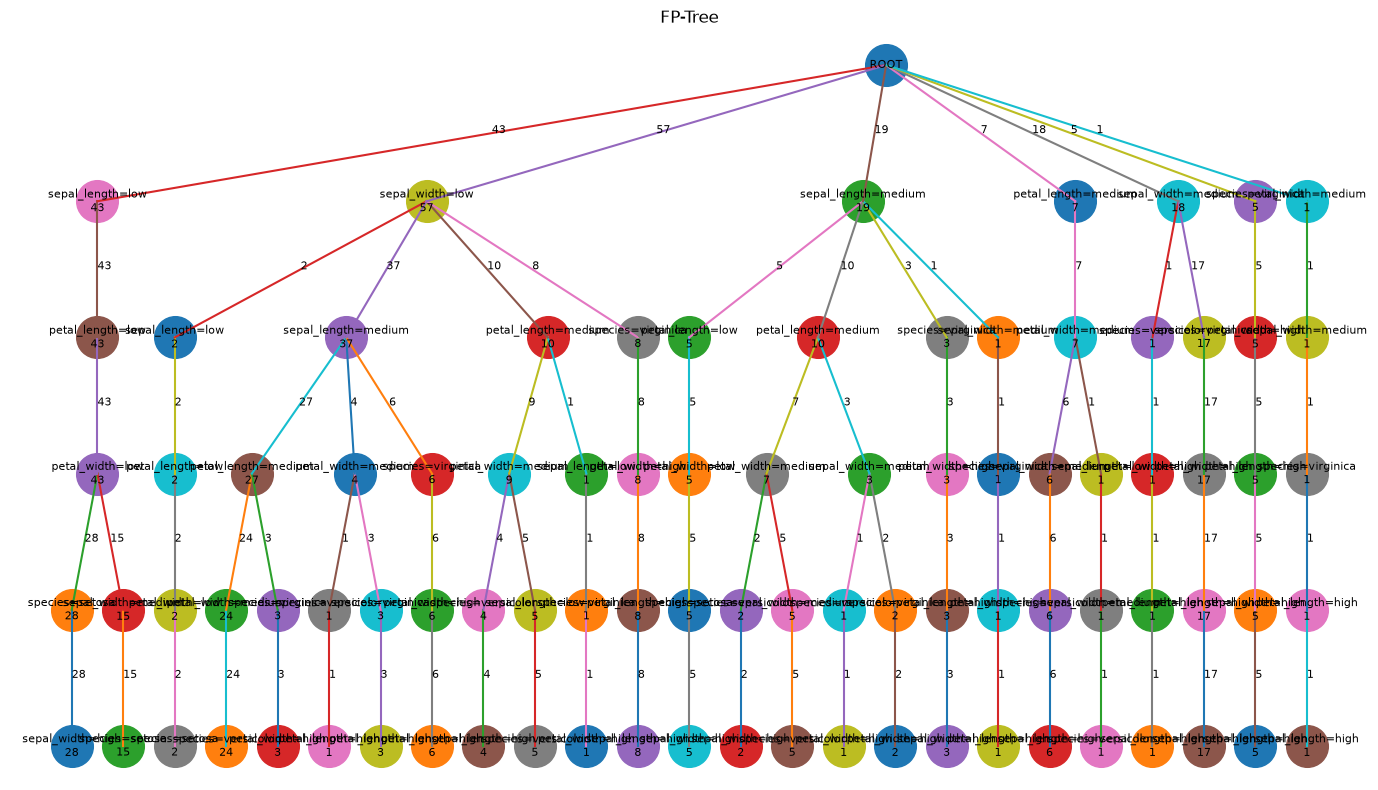

In [30]:
def collect_tree_edges(node, positions=None, edges=None, depth=0):
    if positions is None:
        positions = {}

    if edges is None:
        edges = []

    if node not in positions:
        positions[node] = [0.0, -float(depth)]

    child_nodes = list(node.children.values())

    for child in child_nodes:
        edges.append((node, child))
        collect_tree_edges(
            child,
            positions,
            edges,
            depth + 1
        )

    return positions, edges


def assign_tree_positions(root):
    positions = {}
    next_x = [0]

    def visit(node, depth):
        children = list(node.children.values())

        if not children:
            x = next_x[0]
            next_x[0] += 1
        else:
            child_x = [
                visit(child, depth + 1)
                for child in children
            ]
            x = sum(child_x) / len(child_x)

        positions[node] = (x, -depth)
        return x

    visit(root, 0)
    return positions


positions = assign_tree_positions(fp_tree)

plt.figure(figsize=(14, 8))

for parent in positions:
    for child in parent.children.values():
        x1, y1 = positions[parent]
        x2, y2 = positions[child]

        plt.plot(
            [x1, x2],
            [y1, y2]
        )

        plt.text(
            (x1 + x2) / 2,
            (y1 + y2) / 2,
            str(child.count),
            fontsize=8
        )

for node, (x, y_pos) in positions.items():
    label = "ROOT" if node.item is None else f"{node.item}\n{node.count}"

    plt.scatter([x], [y_pos], s=900)

    plt.text(
        x,
        y_pos,
        label,
        ha="center",
        va="center",
        fontsize=8
    )

plt.title("FP-Tree")
plt.axis("off")
plt.tight_layout()
plt.show()


### Task 19 Observation

The plots show that frequent itemsets are concentrated at smaller sizes, while stricter support and confidence thresholds reduce the number of results. The support-confidence plot also shows that many final rules have very high confidence.

## Task 20: Compare FP-Growth with Apriori

### Task 20 Observation

FP-Growth avoids generating candidate itemsets level by level, unlike Apriori, and uses an FP-tree with conditional mining instead. This can reduce database scans and candidate explosion, although the tree can still use substantial memory.

## Task 21: Algorithmic Complexity and Practical Observation

In [31]:
def count_tree_nodes(tree):
    if tree is None:
        return 0

    count = 1

    for child in tree.children.values():
        count += count_tree_nodes(child)

    return count


main_tree_node_count = count_tree_nodes(fp_tree)

conditional_tree_node_rows = []

for record in conditional_tree_records:
    tree = record["Tree"]

    conditional_tree_node_rows.append({
        "Suffix": record["Suffix"],
        "Conditional Tree Nodes": (
            count_tree_nodes(tree)
            if tree is not None
            else 0
        )
    })

conditional_tree_nodes_df = pd.DataFrame(
    conditional_tree_node_rows
)

print("Main FP-tree node count:", main_tree_node_count)
print("\nConditional FP-tree node counts:")
print(conditional_tree_nodes_df.to_string(index=False))

print("\nFrequent itemsets mined:", len(frequent_itemsets))
print(
    "Maximum itemset size:",
    max(map(len, frequent_itemsets)) if frequent_itemsets else 0
)


Main FP-tree node count: 91

Conditional FP-tree node counts:
             Suffix  Conditional Tree Nodes
    sepal_width=low                       0
sepal_length=medium                       2
petal_length=medium                       4

Frequent itemsets mined: 63
Maximum itemset size: 4


### Task 21 Observation

The main FP-tree has 91 nodes, compared with only 2 and 4 nodes in two of the conditional trees examined. Shared prefixes reduce the tree size, and conditional mining further reduces the search space.

## Task 22: Final Results Table

In [32]:
main_result = {
    "Experiment": "Main FP-Growth run",
    "Setting": f"min support = {MIN_SUPPORT:.2f}",
    "Result": (
        f"Total frequent itemsets = {len(frequent_itemsets)}; "
        f"Largest k = {max(map(len, frequent_itemsets)) if frequent_itemsets else 0}; "
        f"FP-tree nodes = {main_tree_node_count}"
    )
}

rule_result = {
    "Experiment": "Rule generation",
    "Setting": f"min confidence = {MIN_CONFIDENCE:.2f}",
    "Result": f"Number of strong rules = {len(strong_rules)}"
}

support_result = {
    "Experiment": "Support experiment",
    "Setting": "0.15 / 0.20 / 0.25",
    "Result": support_experiment_df.to_dict("records")
}

confidence_result = {
    "Experiment": "Confidence experiment",
    "Setting": "0.50 / 0.70 / 0.90",
    "Result": confidence_experiment_df.to_dict("records")
}

conditional_result = {
    "Experiment": "Conditional mining",
    "Setting": "At least 3 suffix items",
    "Result": conditional_tree_nodes_df.to_dict("records")
}

final_results = pd.DataFrame([
    main_result,
    rule_result,
    support_result,
    confidence_result,
    conditional_result
])

print(final_results.to_string(index=False))


           Experiment                 Setting                                                                                                                                                                                                                                                                                                                                                                                                                                                                              Result
   Main FP-Growth run      min support = 0.20                                                                                                                                                                                                                                                                                                                                                                                                                     Total frequent itemsets = 63; Larges

## Task 23: Observations and Conclusion

### Frequent Itemset Observations

The 20% support run produced 63 frequent itemsets, with patterns up to size 4. Many strong patterns involve petal measurements and species, especially the setosa-related combinations.

### Support and Confidence Observations

Support measures how common a pattern is, while confidence measures how often the consequent appears when the antecedent is present. Several rules reached 100% confidence, but this does not mean the relationship is causal.

### FP-Growth Observations

The FP-tree compresses transactions by sharing common prefixes, and conditional pattern bases focus the search on one suffix at a time. This avoids generating candidate itemsets level by level.

### Effect of Thresholds

Increasing minimum support reduced the number of frequent itemsets from 79 to 63 to 34. Increasing minimum confidence similarly reduced the number of strong rules from 228 to 145 to 95.

### Conclusion

FP-Growth provides a compact way to find frequent patterns and association rules from transaction data. It can be useful for finding co-occurring items in areas such as market-basket analysis and inventory planning.